In [1]:
import pandas as pd
import numpy as np

In [2]:
df=pd.read_csv("C:/Users/Tufail/Desktop/Makshu/Jupyter/CsvFile/DateFruit_Dataset.csv")

In [3]:
df.head()

,AREA,PERIMETER,MAJOR_AXIS,MINOR_AXIS,ECCENTRICITY,EQDIASQ,SOLIDITY,CONVEX_AREA,EXTENT,ASPECT_RATIO,...,KurtosisRR,KurtosisRG,KurtosisRB,EntropyRR,EntropyRG,EntropyRB,ALLdaub4RR,ALLdaub4RG,ALLdaub4RB,Class
0,422163,2378.908,837.8484,645.6693,0.6373,733.1539,0.9947,424428,0.7831,1.2976,...,3.2370,2.9574,4.2287,-59191263232,-50714214400,-39922372608,58.7255,54.9554,47.8400,BERHI
1,338136,2085.144,723.8198,595.2073,0.5690,656.1464,0.9974,339014,0.7795,1.2161,...,2.6228,2.6350,3.1704,-34233065472,-37462601728,-31477794816,50.0259,52.8168,47.8315,BERHI
2,526843,2647.394,940.7379,715.3638,0.6494,819.0222,0.9962,528876,0.7657,1.3150,...,3.7516,3.8611,4.7192,-93948354560,-74738221056,-60311207936,65.4772,59.2860,51.9378,BERHI
3,416063,2351.210,827.9804,645.2988,0.6266,727.8378,0.9948,418255,0.7759,1.2831,...,5.0401,8.6136,8.2618,-32074307584,-32060925952,-29575010304,43.3900,44.1259,41.1882,BERHI
4,347562,2160.354,763.9877,582.8359,0.6465,665.2291,0.9908,350797,0.7569,1.3108,...,2.7016,2.9761,4.4146,-39980974080,-35980042240,-25593278464,52.7743,50.9080,42.6666,BERHI


In [4]:
df.isnull().sum()

AREA             0
PERIMETER        0
MAJOR_AXIS       0
MINOR_AXIS       0
ECCENTRICITY     0
EQDIASQ          0
SOLIDITY         0
CONVEX_AREA      0
EXTENT           0
ASPECT_RATIO     0
ROUNDNESS        0
COMPACTNESS      0
SHAPEFACTOR_1    0
SHAPEFACTOR_2    0
SHAPEFACTOR_3    0
SHAPEFACTOR_4    0
MeanRR           0
MeanRG           0
MeanRB           0
StdDevRR         0
StdDevRG         0
StdDevRB         0
SkewRR           0
SkewRG           0
SkewRB           0
KurtosisRR       0
KurtosisRG       0
KurtosisRB       0
EntropyRR        0
EntropyRG        0
EntropyRB        0
ALLdaub4RR       0
ALLdaub4RG       0
ALLdaub4RB       0
Class            0
dtype: int64

In [5]:
X=df.drop("Class",axis=1)
y=df["Class"]

In [6]:
df["Class"].unique()

<ArrowStringArray>
['BERHI', 'DEGLET', 'DOKOL', 'IRAQI', 'ROTANA', 'SAFAVI', 'SOGAY']
Length: 7, dtype: str

In [7]:
from sklearn.preprocessing import StandardScaler,LabelEncoder

le=LabelEncoder()
y=le.fit_transform(y)

In [8]:
from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test=train_test_split(
    X,y,test_size=0.2,random_state=42
)

In [9]:
scaler=StandardScaler()

X_train_scale=scaler.fit_transform(X_train)
X_test_scale=scaler.transform(X_test)

# ANN

In [10]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader,TensorDataset

In [11]:
X_train_tensor=torch.tensor(X_train_scale,dtype=torch.float32)
y_train_tensor=torch.tensor(y_train,dtype=torch.long)  #when use multiclassification

X_test_tensor=torch.tensor(X_test_scale,dtype=torch.float32)
y_test_tensor=torch.tensor(y_test,dtype=torch.long)

In [12]:
train_dataset=TensorDataset(X_train_tensor,y_train_tensor)
test_dataset=TensorDataset(X_test_tensor,y_test_tensor)

In [13]:
train_loader=DataLoader(train_dataset,batch_size=32,shuffle=True)
test_loader=DataLoader(test_dataset,batch_size=32)

In [14]:
#Model

class ANN(nn.Module):
    def __init__(self):
        super(ANN,self).__init__()

        self.model=nn.Sequential(
            nn.Linear(X.shape[1],64),
            nn.ReLU(),
            nn.Linear(64,64),
            nn.ReLU(),
            nn.Linear(64,7)
        )

    def forward(self,x):
        return self.model(x)

In [15]:
model=ANN()

#loos ,optim
criteria=nn.CrossEntropyLoss()
optimizer=optim.Adam(model.parameters())

In [16]:
# training 
train_losses=[]

epochs=100
for epoch in range(epochs):
    model.train()

    running_loss=0.0

    for xb,yb in train_loader:

        optimizer.zero_grad()
        
        outputs=model(xb)
        loss=criteria(outputs,yb)
        loss.backward()

        optimizer.step()

        running_loss+=loss.item()

    train_loss=running_loss/len(train_loader)
    train_losses.append(train_loss)

    print(f"epoch={epoch}/{epochs},loss={train_loss}")

        

C:\Users\Tufail\AppData\Roaming\Python\Python314\site-packages\torch\autograd\graph.py:1072: UserWarning: CUDA initialization: The NVIDIA driver on your system is too old (found version 11070). Please update your GPU driver by downloading and installing a new version from the URL: http://www.nvidia.com/Download/index.aspx Alternatively, go to: https://pytorch.org to install a PyTorch version that has been compiled with your version of the CUDA driver. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\c10\cuda\CUDAFunctions.cpp:119.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


epoch=0/100,loss=1.646763651267342
epoch=1/100,loss=1.0432666902956755
epoch=2/100,loss=0.7224084346190743
epoch=3/100,loss=0.5487864380297454
epoch=4/100,loss=0.4419192477412846
epoch=5/100,loss=0.38791786976482556
epoch=6/100,loss=0.34225888096767926
epoch=7/100,loss=0.30330285753892816
epoch=8/100,loss=0.28371001456094824
epoch=9/100,loss=0.2638848488745482
epoch=10/100,loss=0.24396156973165015
epoch=11/100,loss=0.23054137502027594
epoch=12/100,loss=0.2176896408200264
epoch=13/100,loss=0.21027719715367194
epoch=14/100,loss=0.19375633027242578
epoch=15/100,loss=0.18868279165547827
epoch=16/100,loss=0.18174545920413473
epoch=17/100,loss=0.17656152954568033
epoch=18/100,loss=0.17082512313904968
epoch=19/100,loss=0.16494802563734676
epoch=20/100,loss=0.15500109092048978
epoch=21/100,loss=0.152158271683299
epoch=22/100,loss=0.14522096044991328
epoch=23/100,loss=0.14059433567783106
epoch=24/100,loss=0.14016101347363513
epoch=25/100,loss=0.1330284549166327
epoch=26/100,loss=0.1284537368008

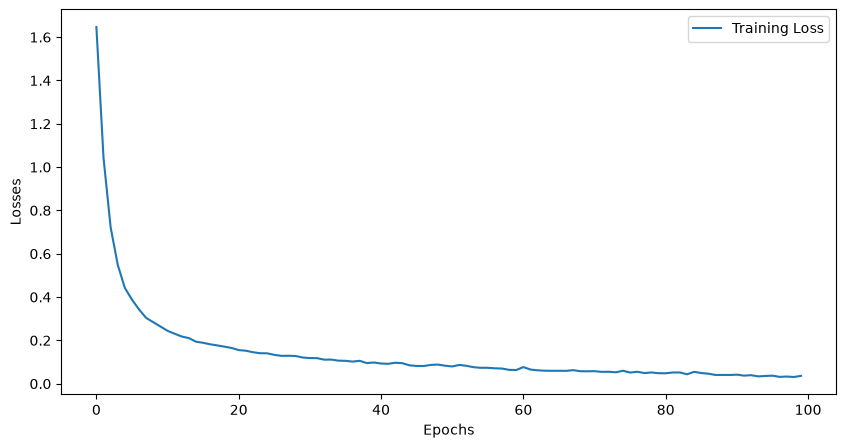

In [17]:
import matplotlib.pyplot as plt

loss_df=pd.DataFrame({
   "Training Loss":train_losses
})

plt.figure(figsize=(10,5))
plt.plot(loss_df["Training Loss"],label="Training Loss")


plt.xlabel("Epochs")
plt.ylabel("Losses")

plt.legend()

In [94]:
#Evaluate

model.eval()

total=0
correct=0

with torch.no_grad():
    for xb,yb in test_loader:
        outputs=model(xb)
        _,predicted=torch.max(outputs,1)

        correct+=(predicted==yb).sum().item()
        total+=yb.size(0)  #actual sample in each batch

print("total val",total)
print("correct pred",correct)

print("accuracy score",correct/total)
        

total val 180
correct pred 169
accuracy score 0.9388888888888889


In [ ]:
#we use pca to reduce dimention of 34